# 01 — EDA & Preprocessing
**Goal:** understand the data before touching a model, pick `MAX_LENGTH` from real token counts,
and write cleaned `train / dev / val` splits for notebooks 02–04.

Runtime: CPU is enough for this notebook (GPU not needed).

> Model inputs are only `channel`, `subject` and `text`. The API never sends `language`,
> so it's used only for analysis, stratification and per-language reporting.

## 1.1 Setup

In [5]:
# --- Environment setup (Colab or local) -------------------------------------------------
import os, sys, json, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    ROOT = Path("/content/drive/MyDrive/TensorForge/training")   # upload the `training/` folder here
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements-colab.txt")], check=True)
else:
    ROOT = Path.cwd().resolve().parent                  # training/notebooks -> training/

sys.path.insert(0, str(ROOT / "src"))
from tfml.paths import Paths
P = Paths(ROOT)
print("ROOT:", P.root, "| raw data:", P.raw_data)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from tfml import data as D
from tfml.labels import CATEGORIES, CHANNELS
pd.set_option("display.max_colwidth", 200)
sns.set_theme(style="whitegrid")

def savefig(name):
    plt.tight_layout(); plt.savefig(P.figures / f"{name}.png", dpi=120); plt.show()

train = D.load_split(P.raw_data / "train.jsonl")
val = D.load_split(P.raw_data / "validation.jsonl")
print(train.shape, val.shape)

ROOT: /content/drive/MyDrive/TensorForge/training | raw data: /content/drive/MyDrive/TensorForge/training/data
(4000, 8) (800, 8)


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1.2 Shape, schema, nulls, CSV ↔ JSONL consistency

In [6]:
for name, df in [("train", train), ("val", val)]:
    print(f"== {name} {df.shape}")
    print(df.dtypes.to_string())
    print("nulls:", df.isna().sum().to_dict())
    print("empty text:", (df.text.str.strip() == "").sum(), "| duplicate ids:", df.ticket_id.duplicated().sum())
print("train/val overlap ids:", len(set(train.ticket_id) & set(val.ticket_id)),
      "| overlap texts:", len(set(train.text) & set(val.text)))

# The CSV has embedded newlines: a proper parser must reproduce the JSONL exactly.
if (P.raw_data / "train.csv").exists():
    csv = D.load_csv_split(P.raw_data / "train.csv")
    j = train.set_index("ticket_id"); c = csv.set_index("ticket_id").loc[j.index]
    same = all((j[col].fillna("__none__").astype(str) == c[col].fillna("__none__").astype(str)).all()
               for col in ["channel", "subject", "text", "category", "secondary_category", "is_urgent"])
    print("CSV rows:", len(csv), "| CSV == JSONL:", same)

== train (4000, 8)
ticket_id             object
channel               object
subject               object
text                  object
language              object
category              object
secondary_category    object
is_urgent               bool
nulls: {'ticket_id': 0, 'channel': 0, 'subject': 0, 'text': 0, 'language': 0, 'category': 0, 'secondary_category': 3600, 'is_urgent': 0}
empty text: 0 | duplicate ids: 0
== val (800, 8)
ticket_id             object
channel               object
subject               object
text                  object
language              object
category              object
secondary_category    object
is_urgent               bool
nulls: {'ticket_id': 0, 'channel': 0, 'subject': 0, 'text': 0, 'language': 0, 'category': 0, 'secondary_category': 720, 'is_urgent': 0}
empty text: 0 | duplicate ids: 0
train/val overlap ids: 0 | overlap texts: 0


## 1.3 Target distribution: `category`

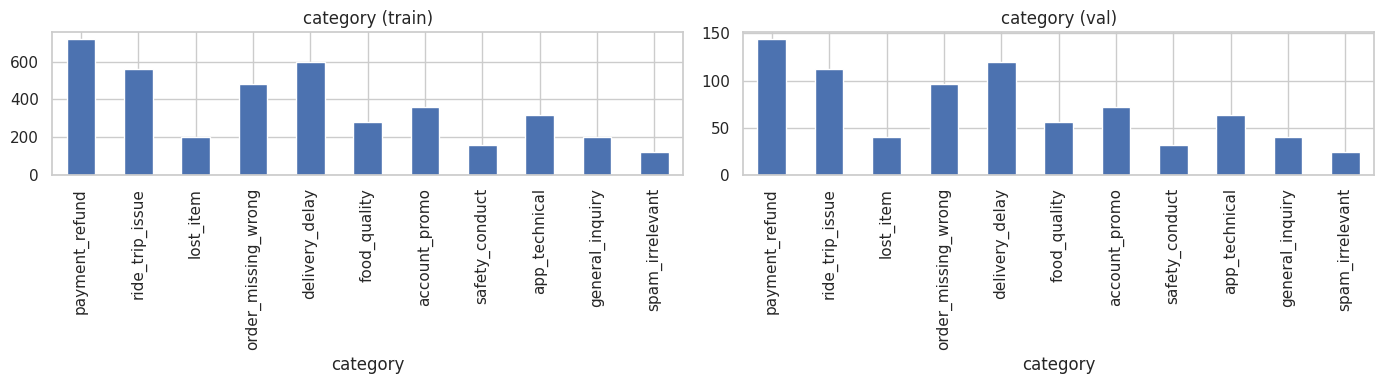

imbalance ratio (max/min): 6.0


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, (name, df) in zip(ax, [("train", train), ("val", val)]):
    df.category.value_counts().reindex(CATEGORIES).plot.bar(ax=a, title=f"category ({name})")
savefig("1_3_category_distribution")
vc = train.category.value_counts()
print("imbalance ratio (max/min):", round(vc.max() / vc.min(), 2))

## 1.4 Secondary category

In [8]:
print("share with a secondary label:", round(train.secondary_category.notna().mean(), 3))
print(train.secondary_category.value_counts().to_string())
combos = train[train.secondary_category.notna()].groupby(["category", "secondary_category"]).size().sort_values(ascending=False)
print("\nmost common (primary, secondary) pairs:\n", combos.head(15).to_string())
print("\nsecondary == primary rows:", (train.secondary_category == train.category).sum())

share with a secondary label: 0.1
secondary_category
ride_trip_issue        135
payment_refund         130
app_technical           45
delivery_delay          45
order_missing_wrong     45

most common (primary, secondary) pairs:
 category             secondary_category 
account_promo        app_technical          45
delivery_delay       payment_refund         45
food_quality         payment_refund         45
lost_item            ride_trip_issue        45
payment_refund       delivery_delay         45
                     ride_trip_issue        45
                     order_missing_wrong    45
safety_conduct       ride_trip_issue        45
order_missing_wrong  payment_refund         40

secondary == primary rows: 0


**Note:** about 90% of tickets have no secondary label, so "secondary accuracy" is easy to inflate
(always predicting `none` already scores about 90%). From here on we report **secondary F1 on present
labels** as well.

## 1.5 Urgency

urgent share: 0.1
is_urgent            False  True 
category                         
payment_refund       0.889  0.111
ride_trip_issue      0.929  0.071
lost_item            0.900  0.100
order_missing_wrong  0.958  0.042
delivery_delay       0.880  0.120
food_quality         0.829  0.171
account_promo        1.000  0.000
safety_conduct       0.250  0.750
app_technical        1.000  0.000
general_inquiry      1.000  0.000
spam_irrelevant      1.000  0.000


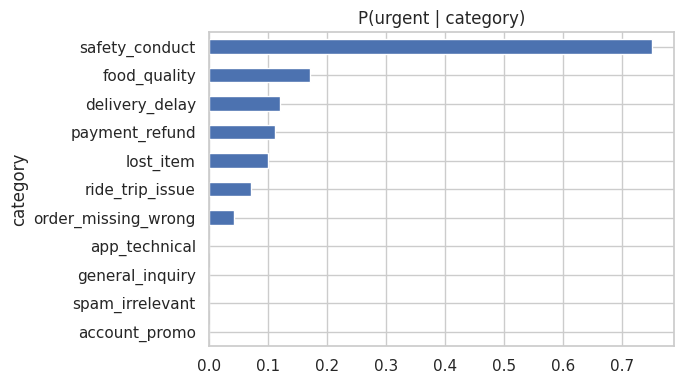

spam urgent: 0 | spam with secondary: 0


In [9]:
print("urgent share:", round(train.is_urgent.mean(), 3))
ct = pd.crosstab(train.category, train.is_urgent, normalize="index").reindex(CATEGORIES)
print(ct.round(3).to_string())
ct[True].sort_values().plot.barh(figsize=(7, 4), title="P(urgent | category)")
savefig("1_5_urgency_by_category")
print("spam urgent:", train[train.category == "spam_irrelevant"].is_urgent.sum(),
      "| spam with secondary:", train[train.category == "spam_irrelevant"].secondary_category.notna().sum())

## 1.6 Language distribution (expected: EN 35%, Singlish 25%, Sinhala 20%, Tamil 15%, Tanglish 2.5%, Mixed 2.5%)

          train    val
language              
en        0.350  0.350
mixed     0.025  0.025
si        0.200  0.200
singlish  0.250  0.250
ta        0.150  0.150
tanglish  0.025  0.025


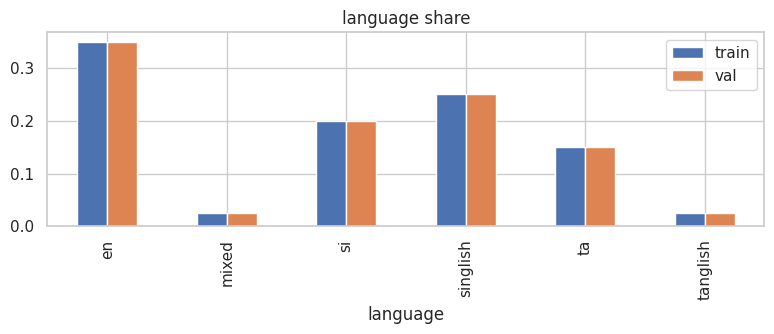

In [10]:
lang = pd.DataFrame({"train": train.language.value_counts(normalize=True), "val": val.language.value_counts(normalize=True)})
print(lang.round(3).to_string())
lang.plot.bar(figsize=(8, 3.5), title="language share"); savefig("1_6_language_distribution")

## 1.7 Channel distribution

channel
chat               1800
email              1200
call_transcript    1000


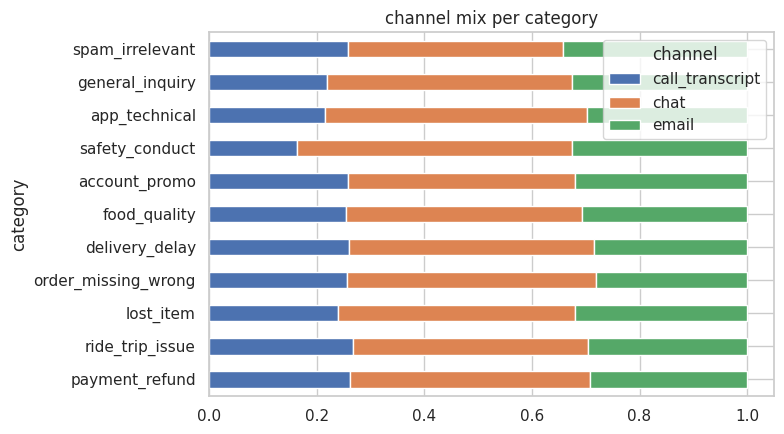

In [11]:
print(train.channel.value_counts().to_string())
assert set(train.channel) <= set(CHANNELS), set(train.channel) - set(CHANNELS)
pd.crosstab(train.category, train.channel, normalize="index").reindex(CATEGORIES).plot.barh(
    stacked=True, figsize=(8, 4.5), title="channel mix per category")
savefig("1_7_channel_by_category")

## 1.8 Text length: characters and tokens → choose `MAX_LENGTH`

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

split          train    val
chars  count  4000.0  800.0
       mean    318.0  328.1
       std     155.3  163.4
       min      36.0   36.0
       25%     197.0  204.0
       50%     275.5  282.0
       75%     406.0  422.5
       max     985.0  937.0
tokens count  4000.0  800.0
       mean     84.3   85.7
       std      34.8   36.3
       min      27.0   28.0
       25%      55.0   55.0
       50%      76.0   78.0
       75%     110.0  112.0
       max     231.0  218.0

tokens by language:
            count  mean   std   min    50%    95%    99%    max
language                                                      
en        1680.0  99.0  42.0  33.0  104.0  168.0  195.0  231.0
mixed      120.0  76.0  24.0  43.0   69.0  123.0  129.0  132.0
si         960.0  69.0  25.0  27.0   64.0  112.0  124.0  146.0
singlish  1200.0  82.0  27.0  32.0   81.0  129.0  143.0  152.0
ta         720.0  76.0  29.0  28.0   70.0  129.0  141.0  158.0
tanglish   120.0  81.0  28.0  28.0   75.0  124.0  137.0  146.

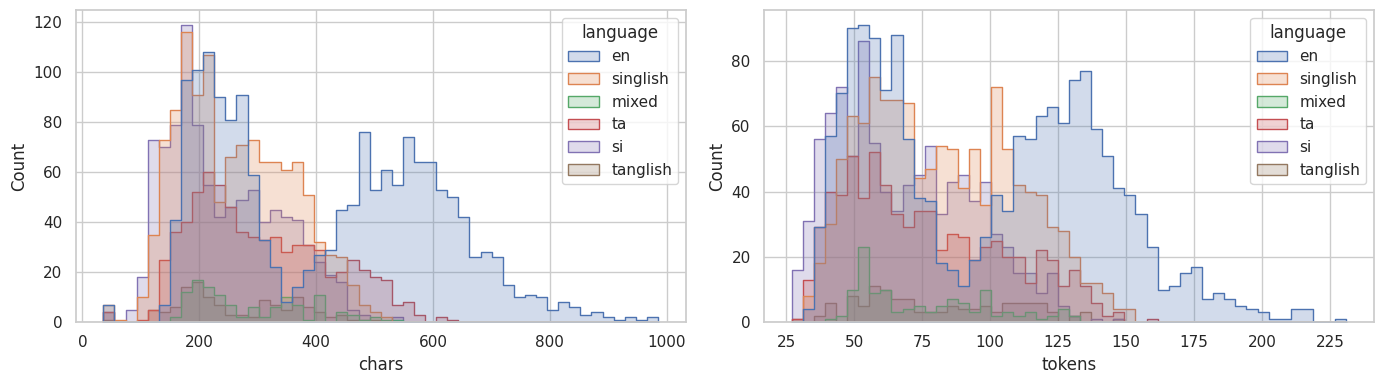

In [12]:
from transformers import AutoTokenizer
# All three transformer candidates share the XLM-R SentencePiece vocabulary,
# so one token count is valid for all of them.
tok = AutoTokenizer.from_pretrained("FacebookAI/xlm-roberta-base")
both = pd.concat([train.assign(split="train"), val.assign(split="val")])
both["chars"] = both.text.str.len()
enc = D.tokenize_frame(tok, D.preprocess(both), max_length=100_000)
both["tokens"] = [len(x) for x in enc["input_ids"]]
print(both.groupby("split")[["chars", "tokens"]].describe().T.round(1).to_string())
print("\ntokens by language:\n", both.groupby("language").tokens.describe(percentiles=[.5, .95, .99]).round(0).to_string())
print("\ntokens by channel:\n", both.groupby("channel").tokens.describe(percentiles=[.5, .95, .99]).round(0).to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(both, x="chars", hue="language", bins=50, ax=ax[0], element="step")
sns.histplot(both, x="tokens", hue="language", bins=50, ax=ax[1], element="step")
savefig("1_8_length_hist")

In [13]:
# MAX_LENGTH: the 99.5th percentile of (header + body) tokens, rounded up to a multiple of 32,
# capped at 512 (encoder limit). The plan's fixed 256 would truncate long Sinhala/Tamil tickets,
# which tokenize into many more pieces than English.
p995 = float(np.percentile(both.tokens, 99.5))
MAX_LENGTH = int(min(512, int(np.ceil(p995 / 32) * 32)))
for L in (256, 320, 384, 448, 512):
    print(f"max_length={L}: truncated {(both.tokens > L).mean():.2%}")
print("p99.5 =", p995, "-> MAX_LENGTH =", MAX_LENGTH)

max_length=256: truncated 0.00%
max_length=320: truncated 0.00%
max_length=384: truncated 0.00%
max_length=448: truncated 0.00%
max_length=512: truncated 0.00%
p99.5 = 188.0050000000001 -> MAX_LENGTH = 192


## 1.9 Subject analysis

In [14]:
has_subj = train.subject.str.strip() != ""
print("empty subject share:", round((~has_subj).mean(), 3))
print(pd.crosstab(train.channel, has_subj, margins=True).to_string())
print("\nexample email subjects per category:")
print(train[has_subj].groupby("category").subject.apply(lambda s: s.sample(min(3, len(s)), random_state=0).tolist()).to_string())

empty subject share: 0.7
subject          False  True   All
channel                           
call_transcript   1000     0  1000
chat              1800     0  1800
email                0  1200  1200
All               2800  1200  4000

example email subjects per category:
category
account_promo                         [Mage message eka, Need an update, Request for assistance]
app_technical                     [Support request, පිළිතුරක් බලාපොරොත්තු වෙමි, Booking details]
delivery_delay                                 [Help ekak, Request for assistance, Refund query]
food_quality           [Help with booking, පිළිතුරක් බලාපොරොත්තු වෙමි, விவரங்களைச் சரிபாருங்கள்]
general_inquiry                                  [Mage message eka, Mage message eka, Help ekak]
lost_item                                          [Help ekak, என் செய்தி, විස්තර පරීක්ෂා කරන්න]
order_missing_wrong                          [මගේ පණිවිඩය, Refund query, Request for assistance]
payment_refund                   [පිළිත

Subjects only exist for `email`, where they are always present. The data notes say *"Read both
subject and body for email"*, so the subject goes into the header segment of the input.

## 1.10 Sample inspection: 2 per language

In [15]:
for lang_, g in train.groupby("language"):
    print(f"\n==================== {lang_} ====================")
    for _, r in g.sample(2, random_state=1).iterrows():
        print(f"[{r.channel}] {r.category} / {r.secondary_category} / urgent={r.is_urgent}")
        print("subject:", r.subject or "-")
        print(r.text[:500], "\n---")


==================== en ====================
[chat] ride_trip_issue / None / urgent=False
subject: -
could
somebody  look into
this for    me drivr accepted trip
and then told  me  to cancel it myself
i was
near  negombo  when  this  happened    pls    tell me
how to  proceed 
---
[chat] lost_item / None / urgent=False
subject: -
could somebody look into this this for me my child's toy was left on the seat after our ride this is the first time i have contacted support about it the reference shown to me is simm-k4t4urk please respond when someone has checked this 
---

==================== mixed ====================
[chat] food_quality / None / urgent=False
subject: -
இது எனக்குப் புரியவில்லை.
கோழி இறைச்சியின் உள்ளே வேகவில்லை, யாரும் சாப்பிடவில்லை.
I checked the confirmation on my phone.
I can provide more details if required.
Please reply when you have checked this. 
---
[email] ride_trip_issue / None / urgent=False
subject: விவரங்களைச் சரிபாருங்கள்
ஒரு உதவி வேண்டும்.

செய்தி எழுதும்ப

## 1.11 Cross-language patterns

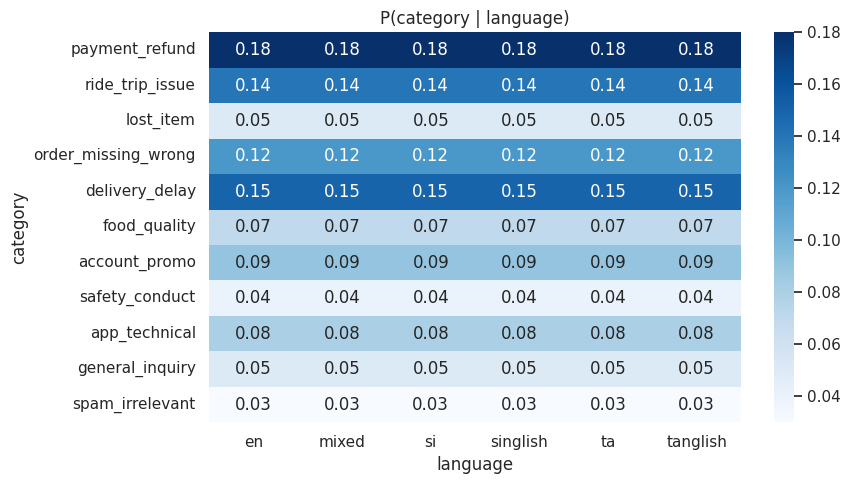

is_urgent  False  True 
language               
en         0.905  0.095
mixed      0.910  0.090
si         0.898  0.102
singlish   0.901  0.099
ta         0.887  0.113
tanglish   0.910  0.090


In [16]:
ct = pd.crosstab(train.category, train.language, normalize="columns").reindex(CATEGORIES)
plt.figure(figsize=(9, 5)); sns.heatmap(ct, annot=True, fmt=".2f", cmap="Blues"); plt.title("P(category | language)")
savefig("1_11_category_by_language")
print(pd.crosstab(train.language, train.is_urgent, normalize="index").round(3).to_string())

## 1.12 Preprocessing and splits
- `clean_text`: Unicode NFC (keeps Sinhala/Tamil combining marks) and whitespace collapsing.
  No lowercasing, emoji or punctuation removal.
- Model input is a sentence pair: `(channel </s> subject, text)`. The real separator token is used and
  truncation only cuts the body (`tfml.textproc.prepare_input`).
- **Dev split (amended plan):** 10% of `train`, stratified by category × language. It's used for epoch selection,
  threshold tuning and calibration. The official `validation` set stays an untouched held-out test.

In [17]:
from tfml.textproc import prepare_input
tr_clean, val_clean = D.preprocess(train), D.preprocess(val)
tr_split, dev_split = D.make_dev_split(tr_clean, dev_frac=0.1, seed=42)
for name, df in [("train", tr_split), ("dev", dev_split), ("val", val_clean)]:
    D.save_jsonl(df, P.processed / f"{name}.jsonl")
    print(f"{name:5s} {len(df):5d}  urgent={df.is_urgent.mean():.3f}  sec={df.secondary_category.notna().mean():.3f}")

print("\nexample model input:", prepare_input(*tr_split.loc[0, ["channel", "subject", "text"]], sep=tok.sep_token))

data_config = {"max_length": MAX_LENGTH, "token_p995": p995, "dev_frac": 0.1, "seed": 42,
               "n_train": len(tr_split), "n_dev": len(dev_split), "n_val": len(val_clean)}
P.data_config.write_text(json.dumps(data_config, indent=2))
print(data_config)

train  3600  urgent=0.098  sec=0.102
dev     400  urgent=0.115  sec=0.077
val     800  urgent=0.100  sec=0.100

example model input: ('email </s> Please check this', 'dear rideeat suport, the amount shown in the record was 1.5k rupees. i have checked the details again before sending this. i am giving as much background as i can remember so the record can be located. i do not remember the exact minute i opened the service, but i have the ref. i tried to explain the sequence to a family member before putting it in writing. i have kept the confirmation rather than deleting it from the device. could somebody look into this for me? my food came from a different restaurant than the one i selected. what happens next? regards, a customer')
{'max_length': 192, 'token_p995': 188.0050000000001, 'dev_frac': 0.1, 'seed': 42, 'n_train': 3600, 'n_dev': 400, 'n_val': 800}


**Output:** `data/processed/{train,dev,val}.jsonl`, `results/data_config.json` (`max_length`), and
figures in `results/figures/`.